# Reto avanzado 2 · Reducción de dimensionalidad y visualización (PCA)

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: resumir el perfil de cada cliente en dos o tres ejes (componentes principales) para poder visualizar la base de clientes y los
segmentos en un gráfico. Este notebook cubre:

1. Carga de datos y librerías
2. Limpieza, agregación a cliente y features derivadas
3. Pipeline de preprocesamiento
4. PCA: varianza explicada en 2D y 3D
5. Pesos de las variables (loadings) y visualización por segmento
6. Regiones estratégicas del plano
7. Valoración: ¿son separables los clústeres?

## 1. Carga de datos y librerías

Partimos del CSV original, con una fila por relación cliente-vehículo. Leemos `client_id` como texto para que no se pierda ningún carácter
del identificador.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (activa la proyección 3D de matplotlib)
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

REF_DATE = pd.Timestamp("2026-10-15")            # fecha de referencia para las antigüedades
raw = pd.read_csv(CSV, low_memory=False, dtype={"client_id": str, "vehicle_id": str, "zipcode": str})
print(f"{len(raw):,} filas · {raw.shape[1]} columnas · {raw.client_id.nunique():,} clientes")

302,850 filas · 39 columnas · 173,456 clientes


## 2. Limpieza, agregación a cliente y features derivadas

### 2.1 Columnas sin valor analítico

Siguiendo las conclusiones del cuaderno 01, eliminamos el índice exportado, el código postal, las modas con varios valores concatenados y los
contadores técnicos. `client_id` y `vehicle_id` no se usan como features, pero los conservamos de momento: el primero para agrupar por cliente
y el segundo para contar sus vehículos.

In [2]:
COLUMNAS_SIN_VALOR = ["Unnamed: 0", "zipcode", "trip_distance_mode", "speed_mode",
                      "trip_distance_all_counter", "speed_all_counter"]
df = raw.drop(columns=COLUMNAS_SIN_VALOR)
print("Columnas eliminadas:", COLUMNAS_SIN_VALOR)

Columnas eliminadas: ['Unnamed: 0', 'zipcode', 'trip_distance_mode', 'speed_mode', 'trip_distance_all_counter', 'speed_all_counter']


### 2.2 Valores nulos

- **Telemetría** (`trip_*`, `speed_*`, horas de uso, consumo): falta en torno al 60 % porque muchos coches no envían datos. No la imputamos;
  la resumimos en el indicador `has_telemetry` (1 si el coche tiene cualquier dato de conducción) y descartamos las métricas.
- **Fechas de matriculación anteriores a 2000** (dos registros de 1987): son imposibles en coches conectados, así que pasan a nulo.
- El resto de nulos de las variables que usaremos (antigüedad del vehículo, poder adquisitivo, gama) se imputan **dentro del pipeline**:
  mediana en las numéricas y moda en las binarias.

In [3]:
TELEMETRIA = ["trip_distance_average", "trip_distance_median", "operating_hours_total",
              "fuel_consumption_average", "speed_average", "speed_median"]
df["has_telemetry_row"] = df[TELEMETRIA].notna().any(axis=1)
df = df.drop(columns=TELEMETRIA)

df["date_of_first_registration"] = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
df.loc[df["date_of_first_registration"] < "2000-01-01", "date_of_first_registration"] = pd.NaT
print(f"Filas con telemetría: {df.has_telemetry_row.mean():.1%}")

Filas con telemetría: 48.2%


### 2.3 Agregación a una fila por cliente

Cada cliente se resume en una fila:

- Los datos propios del cliente (edad, antigüedad, financiación, consentimientos, zona) son iguales en todas sus filas y se copian.
- Los datos del vehículo se toman de su **vehículo principal**: el actual matriculado más recientemente (si no tiene ninguno actual, el más reciente).
- Del historial de la cuenta calculamos el número de vehículos, el total de visitas al taller en garantía, si alguna relación es B2B y si algún
  vehículo tiene telemetría.

In [4]:
filas = df.sort_values(["client_id", "is_current_vehicle", "date_of_first_registration", "vehicle_id"],
                       ascending=[True, False, False, True], na_position="last")

principal = filas.groupby("client_id", sort=True).head(1).set_index("client_id")
historial = (filas.assign(es_b2b=filas["role_type"].eq("B2B"))
                  .groupby("client_id")
                  .agg(n_vehicles_history=("vehicle_id", "nunique"),
                       warranty_visits_total=("workshop_visits_warranty_goodwill", "sum"),
                       is_b2b=("es_b2b", "max"),
                       has_telemetry=("has_telemetry_row", "max")))

COLUMNAS_CLIENTE = ["age_range", "country_code", "months_as_mb_customer", "currently_connected_vehicles",
                    "finance_leasing_status", "consent_epost_communication_channel", "purchasing_power_per_household_eur"]
COLUMNAS_VEHICULO = {"model_class": "main_model_class", "product_group": "main_product_group",
                     "date_of_first_registration": "main_date_of_first_registration"}
clientes = (principal[COLUMNAS_CLIENTE]
            .join(principal[list(COLUMNAS_VEHICULO)].rename(columns=COLUMNAS_VEHICULO))
            .join(historial))
print(f"Tabla de clientes: {clientes.shape[0]:,} filas · {clientes.shape[1]} columnas")

Tabla de clientes: 173,456 filas · 14 columnas


### 2.4 Features derivadas

| Feature | Cálculo |
|---|---|
| `main_vehicle_age_years` | Años entre la matriculación del vehículo principal y la fecha de referencia (15-10-2026) |
| `tenure_years` | Meses como cliente / 12 |
| `itvs_passed_count` | Inspecciones técnicas según la antigüedad y el calendario de cada país: Austria a los 3, 5 y después cada año; Suiza a los 5, 8 y después cada 2 años |
| `warranty_visit_frequency` | Visitas al taller en garantía / vehículos del historial |
| `digital_engagement_index` | Vehículos conectados + 1 si acepta comunicaciones por email |
| `main_is_van` | 1 si el vehículo principal es comercial (`product_group = 'T'`: Sprinter, Vito / V-Class, Citan, X-Class) |

Además codificamos como números tres variables de negocio: el rango de edad (1 = `<25` … 6 = `65+`), la gama del vehículo (1 = compacto …
4 = lujo) y si el cliente tiene financiación activa.

In [5]:
c = clientes
c["main_vehicle_age_years"] = (REF_DATE - c["main_date_of_first_registration"]).dt.days / 365.25
c["tenure_years"] = c["months_as_mb_customer"] / 12

edad = c["main_vehicle_age_years"]
itv_at = np.where(edad < 3, 0, np.where(edad < 5, 1, 2 + np.floor(edad - 5)))
itv_ch = np.where(edad < 5, 0, np.where(edad < 8, 1, 2 + np.floor((edad - 8) / 2)))
c["itvs_passed_count"] = np.where(c["country_code"] == "AT", itv_at, itv_ch)
c.loc[edad.isna(), "itvs_passed_count"] = np.nan                      # sin fecha no se puede estimar

c["warranty_visit_frequency"] = c["warranty_visits_total"] / c["n_vehicles_history"]
c["digital_engagement_index"] = c["currently_connected_vehicles"] + c["consent_epost_communication_channel"].astype(int)
c["main_is_van"] = c["main_product_group"].eq("T").astype(int)

c["age_ord"] = c["age_range"].map(mf.AGE_ORDER)
c["main_segment_tier"] = c["main_model_class"].map(mf.SEGMENT_TIER)
c["finance_active"] = c["finance_leasing_status"].str.startswith("active").astype(int)
c["is_b2b"] = c["is_b2b"].astype(int)
c["has_telemetry"] = c["has_telemetry"].astype(int)

DERIVADAS = ["main_vehicle_age_years", "tenure_years", "itvs_passed_count", "warranty_visit_frequency",
             "digital_engagement_index", "main_is_van"]
c[DERIVADAS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
main_vehicle_age_years,171910.0,4.63,3.01,0.04,2.2,4.24,6.67,26.33
tenure_years,173454.0,2.82,1.73,0.00,1.5,3.00,3.92,10.00
itvs_passed_count,171910.0,1.05,1.61,0.00,0.0,0.00,1.00,19.00
warranty_visit_frequency,173456.0,2.09,2.35,0.00,0.0,1.50,3.00,36.33
digital_engagement_index,173456.0,2.02,0.89,0.00,2.0,2.00,2.00,22.00
main_is_van,173456.0,0.11,0.31,0.00,0.0,0.00,0.00,1.00


## 3. Pipeline de preprocesamiento

### 3.1 Selección de features

Partimos de 15 candidatas de negocio y eliminamos las que están casi duplicadas: si dos variables tienen una correlación de Spearman superior
a 0,85, medirían lo mismo y en el PCA contarían dos veces. De cada pareja conservamos la más útil para marketing (la que aparece antes en la lista).

In [6]:
CANDIDATAS = [   # ordenadas por prioridad de negocio
    "main_vehicle_age_years", "tenure_years", "warranty_visit_frequency", "digital_engagement_index",
    "purchasing_power_per_household_eur", "n_vehicles_history", "age_ord", "main_segment_tier",
    "main_is_van", "has_telemetry", "is_b2b", "finance_active",
    "itvs_passed_count", "warranty_visits_total", "currently_connected_vehicles",
]
corr = c[CANDIDATAS].corr(method="spearman").abs()
FEATURES, descartadas = [], []
for f in CANDIDATAS:
    pareja = next((g for g in FEATURES if corr.loc[f, g] > 0.85), None)
    if pareja is None:
        FEATURES.append(f)
    else:
        descartadas.append({"descartada": f, "muy correlacionada con": pareja, "ρ": round(corr.loc[f, pareja], 2)})
pd.DataFrame(descartadas).to_csv(ROOT / "reports" / "A2_features_descartadas.csv", index=False)
display(pd.DataFrame(descartadas))
print(f"Features finales ({len(FEATURES)}):", FEATURES)

,descartada,muy correlacionada con,ρ
0,itvs_passed_count,main_vehicle_age_years,0.86
1,warranty_visits_total,warranty_visit_frequency,0.93
2,currently_connected_vehicles,digital_engagement_index,0.96


Features finales (12): ['main_vehicle_age_years', 'tenure_years', 'warranty_visit_frequency', 'digital_engagement_index', 'purchasing_power_per_household_eur', 'n_vehicles_history', 'age_ord', 'main_segment_tier', 'main_is_van', 'has_telemetry', 'is_b2b', 'finance_active']


Las tres descartadas son redundantes por construcción: las inspecciones se calculan a partir de la antigüedad del coche, el total de visitas
es la base de la frecuencia de visitas y los vehículos conectados forman parte del índice digital.

### 3.2 ColumnTransformer

- **Continuas con asimetría fuerte** (asimetría mayor que 1): mediana para los nulos → `log1p` para comprimir la cola larga → `StandardScaler`.
- **Resto de continuas y ordinales**: mediana → `StandardScaler`.
- **Binarias**: moda para los nulos y se dejan en 0/1.

El escalado es imprescindible en PCA: el análisis busca las direcciones de mayor varianza, y sin escalar el poder adquisitivo (en euros)
acapararía toda la varianza solo por sus unidades.

In [7]:
BINARIAS = [f for f in FEATURES if set(c[f].dropna().unique()) <= {0, 1}]
CONTINUAS = [f for f in FEATURES if f not in BINARIAS]
asimetria = c[CONTINUAS].skew()
ASIMETRICAS = [f for f in CONTINUAS if abs(asimetria[f]) > 1]
SIMETRICAS = [f for f in CONTINUAS if f not in ASIMETRICAS]
print("Asimetría:", asimetria.round(2).to_dict())
print("log1p + StandardScaler:", ASIMETRICAS)
print("StandardScaler:", SIMETRICAS)
print("Binarias (0/1):", BINARIAS)

preprocesado = ColumnTransformer([
    ("asimetricas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                              ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("escalar", StandardScaler())]), ASIMETRICAS),
    ("continuas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]), SIMETRICAS),
    ("binarias", SimpleImputer(strategy="most_frequent"), BINARIAS),
], verbose_feature_names_out=False)

X_scaled = preprocesado.fit_transform(c[FEATURES])
nombres = preprocesado.get_feature_names_out()
print(f"\nMatriz procesada: {X_scaled.shape[0]:,} clientes × {X_scaled.shape[1]} features · nulos: {int(np.isnan(X_scaled).sum())}")

Asimetría: {'main_vehicle_age_years': 0.66, 'tenure_years': 0.4, 'warranty_visit_frequency': 1.84, 'digital_engagement_index': 10.4, 'purchasing_power_per_household_eur': 1.67, 'n_vehicles_history': 34.32, 'age_ord': -0.18, 'main_segment_tier': 0.62}
log1p + StandardScaler: ['warranty_visit_frequency', 'digital_engagement_index', 'purchasing_power_per_household_eur', 'n_vehicles_history']
StandardScaler: ['main_vehicle_age_years', 'tenure_years', 'age_ord', 'main_segment_tier']
Binarias (0/1): ['main_is_van', 'has_telemetry', 'is_b2b', 'finance_active']



Matriz procesada: 173,456 clientes × 12 features · nulos: 0


## 4. PCA: varianza explicada en 2D y 3D

El PCA busca nuevas variables (componentes principales) que son combinaciones de las originales: la primera recoge la dirección en la que los
clientes más se diferencian, la segunda la siguiente (independiente de la primera), y así sucesivamente. La **varianza explicada** indica qué
parte de la información total conserva cada componente.

In [8]:
pca = PCA(n_components=3, random_state=42)
componentes = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_

for i, v in enumerate(var, start=1):
    print(f"PC{i}: {v:.1%} de la varianza")
print(f"\nVarianza acumulada en 2D (PC1 + PC2):       {var[:2].sum():.1%}")
print(f"Varianza acumulada en 3D (PC1 + PC2 + PC3): {var.sum():.1%}")

df_pca = pd.DataFrame(componentes, columns=["PC1", "PC2", "PC3"], index=c.index)
df_pca.head()

PC1: 22.5% de la varianza
PC2: 16.7% de la varianza
PC3: 12.5% de la varianza

Varianza acumulada en 2D (PC1 + PC2):       39.2%
Varianza acumulada en 3D (PC1 + PC2 + PC3): 51.7%


,PC1,PC2,PC3
client_id,,,
0000eb1785b60456d8ca6059563d61ad9ec480b63d69f616478bc9eb50510d33,0.217606,0.132113,0.308898
000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,0.403302,-0.964798,0.845679
00017f3423e3110fffd0e920f7bc09af8be9e76afd000486fba5946417888eb5,-0.603642,-2.475567,-0.641611
0002237881f9c8edb669596513bd0fda1840f744be43826b88e7132d476e1a69,0.329142,0.460966,-1.117243
00025c8e89802884b50161dd460faab34f9cff05781f17d62cb8167c75278383,0.968579,-0.163181,-0.469826


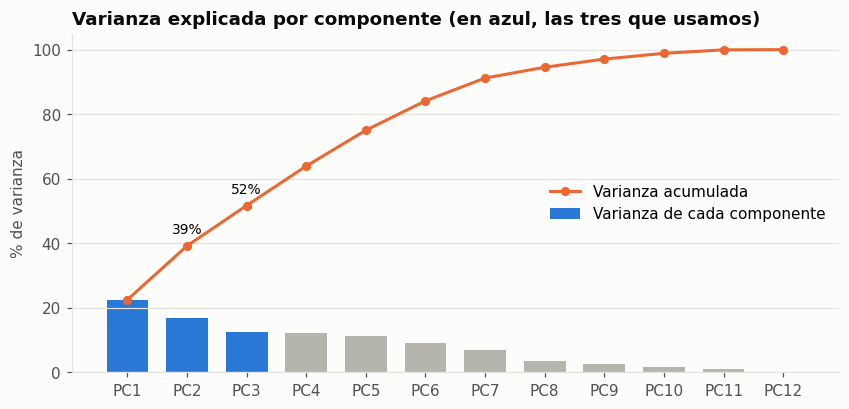

Componentes necesarias para conservar el 80 % de la varianza: 6 de 12


In [9]:
# Contexto: ¿cuántas componentes harían falta para conservar más información?
pca_total = PCA(random_state=42).fit(X_scaled)
acum = np.cumsum(pca_total.explained_variance_ratio_)
pd.DataFrame({"varianza_%": pca_total.explained_variance_ratio_ * 100, "acumulada_%": acum * 100},
             index=[f"PC{i}" for i in range(1, len(acum) + 1)]).to_csv(ROOT / "reports" / "A2_varianza.csv")

fig, ax = plt.subplots(figsize=(9, 4))
k = np.arange(1, len(acum) + 1)
ax.bar(k, pca_total.explained_variance_ratio_ * 100, color=[ps.SERIES[0] if i <= 3 else "#b5b4ad" for i in k], width=0.7,
       label="Varianza de cada componente")
ax.plot(k, acum * 100, color=ps.SERIES[1], marker="o", ms=5, lw=2, label="Varianza acumulada")
for i in (2, 3):
    ax.annotate(f"{acum[i - 1]:.0%}", (i, acum[i - 1] * 100), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(k, [f"PC{i}" for i in k]); ax.set_ylabel("% de varianza"); ax.set_ylim(0, 105); ax.legend(loc="center right")
ax.set_title("Varianza explicada por componente (en azul, las tres que usamos)")
fig.savefig(FIG_DIR / "A2_varianza_pca.png"); plt.show()
print(f"Componentes necesarias para conservar el 80 % de la varianza: {int(np.argmax(acum >= 0.8)) + 1} de {len(acum)}")

El plano PC1-PC2 conserva algo menos del 40 % de la información y el espacio 3D, algo más de la mitad. Es razonable para **visualizar**: los
clientes se describen con muchas dimensiones poco correlacionadas entre sí, así que ningún par de ejes puede resumirlas todas. Por eso los
gráficos sirven para ver tendencias generales, pero no muestran todas las diferencias entre clientes.

## 5. Pesos de las variables (loadings) y visualización

### 5.1 ¿Qué mide cada componente?

Los **loadings** son el peso de cada variable original en cada componente. Un peso alto (positivo o negativo) indica que esa variable define el
eje; el signo indica en qué dirección.

,PC1,PC2,PC3
tenure_years,0.53,0.30,0.34
n_vehicles_history,0.48,-0.41,0.07
digital_engagement_index,0.46,-0.34,0.11
warranty_visit_frequency,0.41,0.52,-0.10
main_vehicle_age_years,-0.21,0.42,0.61
purchasing_power_per_household_eur,0.15,0.41,-0.50
main_segment_tier,0.09,-0.00,0.06
has_telemetry,0.09,0.01,0.05
finance_active,0.09,-0.04,-0.09
age_ord,0.05,0.09,-0.48


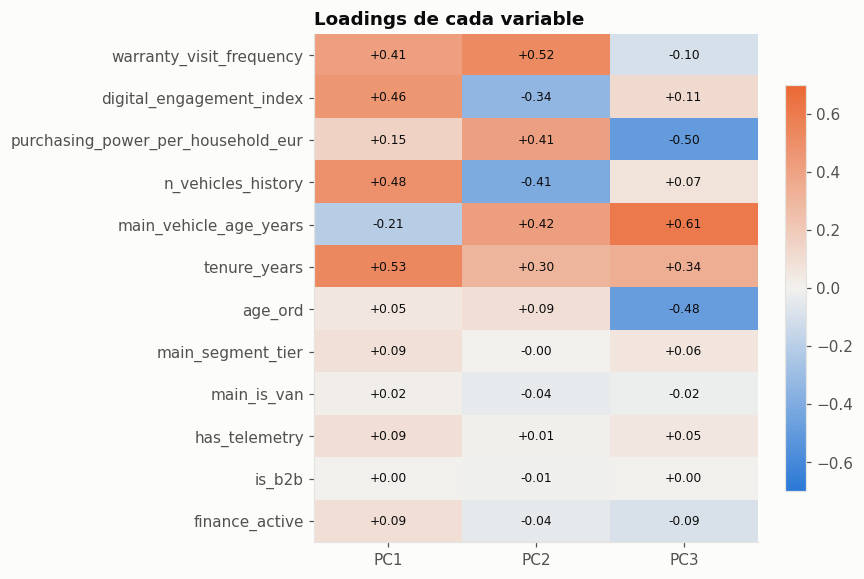

In [10]:
loadings = pd.DataFrame(pca.components_.T, index=nombres, columns=["PC1", "PC2", "PC3"])
display(loadings.round(2).sort_values("PC1", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(loadings.values, cmap=ps.DIVERGING, vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(3), loadings.columns); ax.set_yticks(range(len(loadings)), loadings.index); ax.grid(False)
for i in range(loadings.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{loadings.values[i, j]:+.2f}", ha="center", va="center", fontsize=8, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Loadings de cada variable")
fig.savefig(FIG_DIR / "A2_loadings.png"); plt.show()

**Interpretación de los ejes:**

- **PC1 · Profundidad de la relación con la marca.** Pesan en positivo la antigüedad como cliente, el número de vehículos en el historial, el
  índice digital y las visitas al taller. A la derecha están los clientes veteranos, con varios coches, conectados y que usan la posventa; a la
  izquierda, los recién llegados con un solo vehículo.
- **PC2 · Cliente maduro de posventa frente a cliente multi-vehículo.** Pesan en positivo las visitas al taller, la antigüedad del coche y el poder
  adquisitivo, y en negativo el número de vehículos y el índice digital. Arriba está el cliente con un coche que ya tiene años y lo mantiene en el
  taller oficial; abajo, el cliente con varios coches conectados.
- **PC3 · Coche antiguo en manos de clientes jóvenes.** Pesa en positivo la antigüedad del coche y en negativo la edad del cliente y el poder
  adquisitivo: destaca a los clientes jóvenes, con menos renta y un vehículo con años.

Las variables binarias (furgoneta, telemetría, B2B, financiación) apenas pesan. Al dejarlas en 0/1 su varianza es mucho menor que la de las
continuas estandarizadas, así que no definen ningún eje. Es una consecuencia buscada: evita que una característica minoritaria, como B2B, domine
la proyección.

### 5.2 Segmento de cada cliente

Para interpretar los gráficos coloreamos cada cliente por el **segmento** que le asignó K-Means en el cuaderno 03 (`clientes_clusters.csv`) y,
si está disponible, con el nombre de negocio del cuaderno 04 (`clientes_segmentos_k6.csv`).

El cruce se hace por `client_id` y se comprueba con `assert` que no se pierde ni se duplica ningún cliente: si algo no cuadrara, el cuaderno se
detendría aquí en lugar de dibujar gráficos con datos incorrectos.

In [11]:
FICHERO_CLUSTERS = DATA_DIR / "clientes_clusters.csv"
FICHERO_NOMBRES = DATA_DIR / "clientes_segmentos_k6.csv"
hay_clusters = FICHERO_CLUSTERS.exists()

if hay_clusters:
    etiquetas = pd.read_csv(FICHERO_CLUSTERS, usecols=["client_id", "cluster"], dtype={"client_id": str})
    assert etiquetas["client_id"].is_unique, "clientes_clusters.csv tiene client_id duplicados"
    assert set(etiquetas["client_id"]) == set(df_pca.index), "los clientes del PCA y de los clústeres no coinciden"

    n_antes = len(df_pca)
    df_pca = (df_pca.reset_index()
                    .merge(etiquetas, on="client_id", how="left", validate="one_to_one")
                    .set_index("client_id"))
    assert len(df_pca) == n_antes and df_pca["cluster"].notna().all(), "el cruce ha perdido o duplicado clientes"

    if FICHERO_NOMBRES.exists():
        nombres = pd.read_csv(FICHERO_NOMBRES, usecols=["cluster", "segmento"]).drop_duplicates()
        assert nombres["cluster"].is_unique, "un clúster tiene más de un nombre"
        NOMBRE = dict(zip(nombres["cluster"], nombres["segmento"]))
    else:
        NOMBRE = {c: f"Clúster {c}" for c in df_pca["cluster"].unique()}
    df_pca["segmento"] = [f"{c} · {NOMBRE[c]}" for c in df_pca["cluster"]]
    ORDEN_SEG = sorted(df_pca["segmento"].unique())
    PALETA = dict(zip(ORDEN_SEG, ps.SERIES))
    print(f"Clientes con segmento: {df_pca['segmento'].notna().mean():.0%} de {len(df_pca):,}")
    display(df_pca["segmento"].value_counts().reindex(ORDEN_SEG).rename("clientes").to_frame())
else:
    print("No se ha encontrado clientes_clusters.csv: ejecuta antes el cuaderno 03. Los gráficos se dibujarán sin colorear.")

Clientes con segmento: 100% de 173,456


,clientes
segmento,
0 · El Sénior Recién Llegado,29388
1 · El Ejecutivo Premium AMG,26245
2 · El Conductor en Leasing,31980
3 · El Joven Aspiracional,30809
4 · El Veterano a Renovar,21510
5 · El Fiel del Taller Oficial,33524


### 5.3 Gráfico 2D (PC1 frente a PC2) por segmento

Dibujamos una muestra aleatoria de 25.000 clientes: con los 173.456 los puntos se taparían unos a otros. Los ejes se limitan al rango donde
está el 99 % de los clientes, porque unas pocas cuentas con muchos vehículos quedan muy alejadas y aplastarían la nube. La función
`grafico_pca_2d` recibe en `hue` la columna con la que colorear (aquí, el segmento).

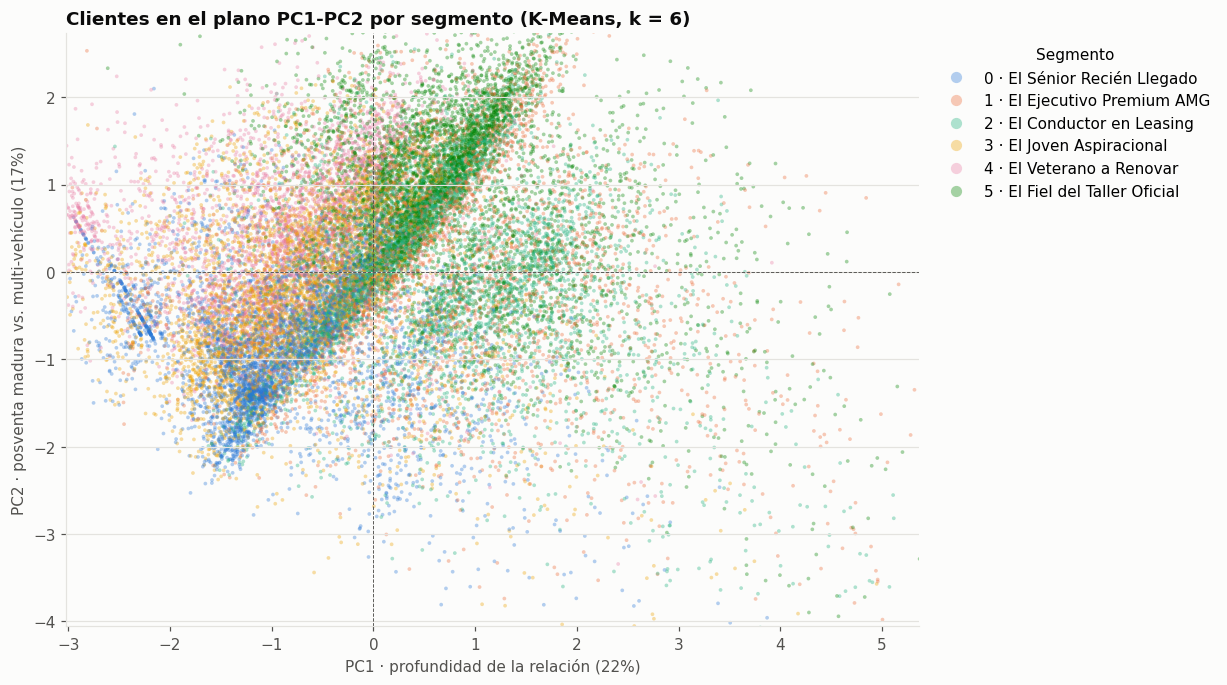

In [12]:
MUESTRA = df_pca.sample(25_000, random_state=42).index

def grafico_pca_2d(datos, hue=None, titulo="Clientes en el plano PC1-PC2", fichero=None, paleta=None):
    # Scatter PC1 vs PC2. Si `hue` es el nombre de una columna de `datos`, colorea por ella (p. ej. el segmento).
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.scatterplot(data=datos, x="PC1", y="PC2", hue=hue, hue_order=list(paleta) if paleta else None, palette=paleta,
                    s=6, alpha=0.35, linewidth=0, ax=ax, color=None if hue else ps.SERIES[0])
    # Ejes limitados al rango del 99 % central de los clientes: unos pocos extremos (cuentas con muchos coches) aplastarían la nube
    ax.set_xlim(*df_pca["PC1"].quantile([0.005, 0.995])); ax.set_ylim(*df_pca["PC2"].quantile([0.005, 0.995]))
    ax.axhline(0, color=ps.INK_2, lw=0.6, ls="--"); ax.axvline(0, color=ps.INK_2, lw=0.6, ls="--")
    ax.set_xlabel(f"PC1 · profundidad de la relación ({var[0]:.0%})")
    ax.set_ylabel(f"PC2 · posventa madura vs. multi-vehículo ({var[1]:.0%})")
    ax.set_title(titulo)
    if hue:
        ax.legend(title="Segmento", markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
    if fichero:
        fig.savefig(FIG_DIR / fichero)
    plt.show()

if hay_clusters:
    grafico_pca_2d(df_pca.loc[MUESTRA], hue="segmento", paleta=PALETA,
                   titulo="Clientes en el plano PC1-PC2 por segmento (K-Means, k = 6)", fichero="A2_pca_2d_clusters.png")
else:
    grafico_pca_2d(df_pca.loc[MUESTRA], fichero="A2_pca_2d.png")

Los clientes forman una nube continua, más densa cerca del origen, sin islas separadas. Aun así, los colores muestran **tendencias claras**:
los segmentos con una relación más profunda con la marca se concentran a la derecha y los recién llegados y los más jóvenes, a la izquierda.
Las zonas de cada segmento se solapan en los bordes, algo que cuantificamos en la sección 7.

### 5.4 Gráfico 3D (PC1, PC2 y PC3) por segmento

El tercer eje (PC3) separa a los clientes con coche antiguo y menos renta: añade la dimensión que el plano 2D no muestra.

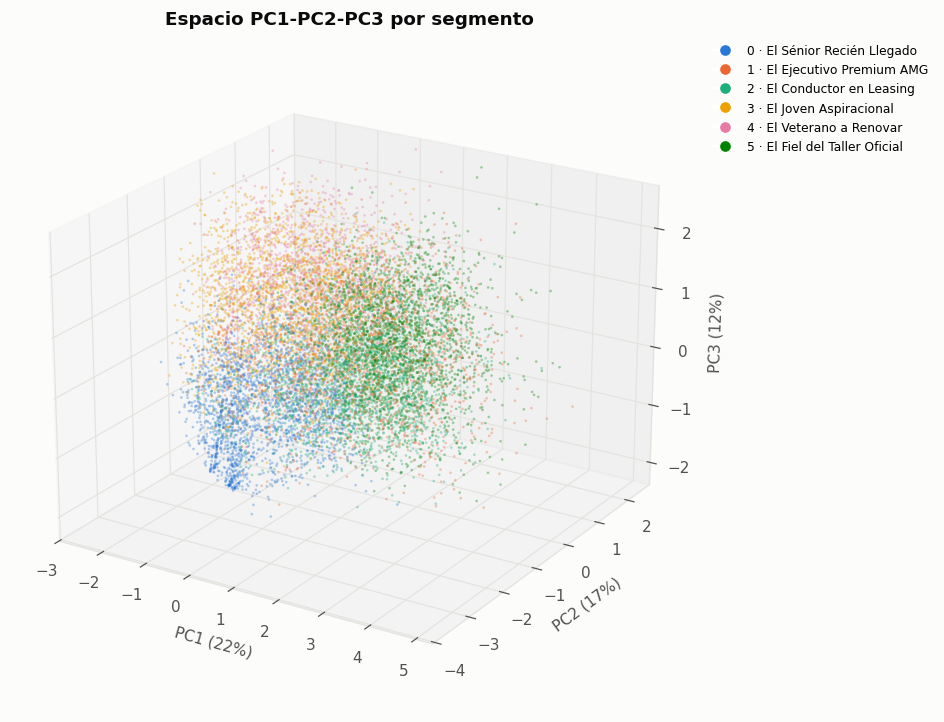

In [13]:
from matplotlib.lines import Line2D

def grafico_pca_3d(datos, colores=None, titulo="Clientes en el espacio PC1-PC2-PC3", fichero=None, leyenda=None):
    # En 3D matplotlib no recorta los puntos fuera de los ejes: dibujamos solo el 99 % central de los clientes
    limites = {pc: df_pca[pc].quantile([0.005, 0.995]).to_numpy() for pc in ["PC1", "PC2", "PC3"]}
    dentro = np.logical_and.reduce([datos[pc].between(*lim) for pc, lim in limites.items()])
    datos = datos[dentro]
    if colores is not None:
        colores = colores[dentro]
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(datos["PC1"], datos["PC2"], datos["PC3"], c=colores if colores is not None else ps.SERIES[0],
               s=3, alpha=0.35, linewidths=0)
    ax.set_xlabel(f"PC1 ({var[0]:.0%})"); ax.set_ylabel(f"PC2 ({var[1]:.0%})"); ax.set_zlabel(f"PC3 ({var[2]:.0%})")
    for eje, pc in zip("xyz", ["PC1", "PC2", "PC3"]):
        getattr(ax, f"set_{eje}lim")(*limites[pc])
    ax.view_init(elev=22, azim=-58)
    ax.set_title(titulo)
    if leyenda:
        ax.legend(handles=leyenda, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    if fichero:
        fig.savefig(FIG_DIR / fichero)
    plt.show()

m3 = MUESTRA[:12_000]
if hay_clusters:
    leyenda = [Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETA[s], markersize=8, label=s) for s in ORDEN_SEG]
    grafico_pca_3d(df_pca.loc[m3], colores=df_pca.loc[m3, "segmento"].map(PALETA),
                   titulo="Espacio PC1-PC2-PC3 por segmento", fichero="A2_pca_3d_clusters.png", leyenda=leyenda)
else:
    grafico_pca_3d(df_pca.loc[m3], fichero="A2_pca_3d.png")

## 6. Regiones estratégicas del plano

Para saber qué zonas del plano concentran a los clientes más valiosos, calculamos la **posición media de cada segmento** y la cruzamos con
indicadores de valor de esos clientes: poder adquisitivo, uso del taller oficial, antigüedad como cliente, gama del vehículo y financiación.
No disponemos de datos de facturación, así que estos indicadores son la mejor aproximación disponible al **valor** de cada perfil.

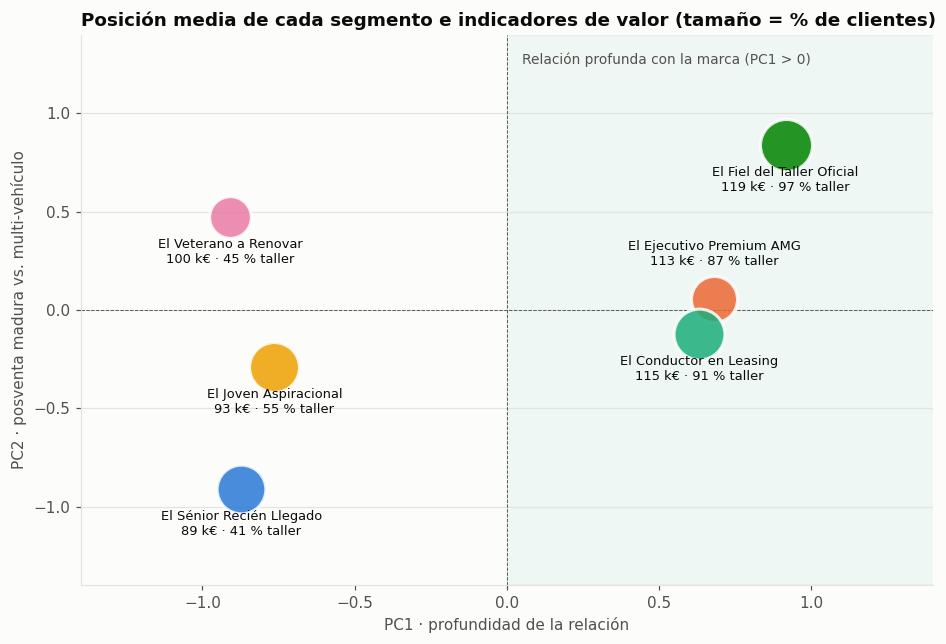

,PC1,PC2,clientes_pct,poder_adquisitivo_k,posventa_pct,meses_cliente,gama_superior_pct,financiacion_activa_pct
segmento,,,,,,,,
0 · El Sénior Recién Llegado,-0.87,-0.91,16.94,89.10,40.54,15.04,6.00,9.80
1 · El Ejecutivo Premium AMG,0.68,0.06,15.13,112.80,87.09,38.59,99.97,35.10
2 · El Conductor en Leasing,0.63,-0.12,18.44,114.71,90.91,37.17,0.00,96.30
3 · El Joven Aspiracional,-0.76,-0.29,17.76,93.45,55.33,26.82,2.80,2.55
4 · El Veterano a Renovar,-0.91,0.47,12.40,100.16,45.05,30.58,39.51,1.58
5 · El Fiel del Taller Oficial,0.92,0.84,19.33,118.54,97.09,52.28,0.76,4.17


In [14]:
if hay_clusters:
    perfil = pd.read_csv(FICHERO_CLUSTERS, dtype={"client_id": str}, low_memory=False,
                         usecols=["client_id", "purchasing_power_per_household_eur", "workshop_visits_total",
                                  "months_as_mb_customer", "main_model_class", "finance_leasing_status"])
    assert perfil["client_id"].is_unique
    perfil = perfil.merge(df_pca[["segmento", "PC1", "PC2", "PC3"]].reset_index(), on="client_id", how="inner", validate="one_to_one")
    assert len(perfil) == len(df_pca), "el cruce ha perdido clientes"

    perfil["gama_superior"] = perfil["main_model_class"].map(mf.SEGMENT_TIER) >= 3
    regiones = perfil.groupby("segmento").agg(
        PC1=("PC1", "mean"), PC2=("PC2", "mean"),
        clientes_pct=("PC1", lambda x: len(x) / len(perfil) * 100),
        poder_adquisitivo_k=("purchasing_power_per_household_eur", lambda x: x.mean() / 1000),
        posventa_pct=("workshop_visits_total", lambda x: (x > 0).mean() * 100),
        meses_cliente=("months_as_mb_customer", "mean"),
        gama_superior_pct=("gama_superior", lambda x: x.mean() * 100),
        financiacion_activa_pct=("finance_leasing_status", lambda x: x.str.startswith("active").mean() * 100),
    ).reindex(ORDEN_SEG)
    regiones.to_csv(ROOT / "reports" / "A2_regiones_segmentos.csv")

    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.axvspan(0, 10, color=ps.SERIES[2], alpha=0.06)
    ax.text(0.05, 1.25, "Relación profunda con la marca (PC1 > 0)", fontsize=9, color=ps.INK_2)
    for seg, fila in regiones.iterrows():
        ax.scatter(fila.PC1, fila.PC2, s=fila.clientes_pct * 60, color=PALETA[seg], alpha=0.85, edgecolor="white", linewidth=2, zorder=3)
        # Si otro segmento está muy cerca y por debajo, la etiqueta va encima para que no se pisen
        cerca_debajo = ((regiones.PC1 - fila.PC1).abs() < 0.4) & ((regiones.PC2 - fila.PC2).abs() < 0.4) & (regiones.PC2 < fila.PC2)
        arriba = cerca_debajo.any()
        ax.annotate(f"{seg.split(' · ')[1]}\n{fila.poder_adquisitivo_k:.0f} k€ · {fila.posventa_pct:.0f} % taller",
                    (fila.PC1, fila.PC2), xytext=(0, 20 if arriba else -30), textcoords="offset points", ha="center",
                    va="bottom" if arriba else "baseline", fontsize=8.5, color=ps.INK)
    ax.axhline(0, color=ps.INK_2, lw=0.6, ls="--"); ax.axvline(0, color=ps.INK_2, lw=0.6, ls="--")
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
    ax.set_xlabel("PC1 · profundidad de la relación"); ax.set_ylabel("PC2 · posventa madura vs. multi-vehículo")
    ax.set_title("Posición media de cada segmento e indicadores de valor (tamaño = % de clientes)")
    fig.savefig(FIG_DIR / "A2_centros_clusters.png"); plt.show()
    display(regiones.round(2))

**Qué regiones ocupan los perfiles más estratégicos:**

- **La mitad derecha (PC1 > 0) es la zona de mayor valor.** Ahí se sitúan el Fiel del Taller Oficial, el Ejecutivo Premium AMG y el Conductor
  en Leasing: los tres segmentos con mayor poder adquisitivo y con casi todos sus clientes usando el taller oficial. Juntos suman algo más de la
  mitad de la base y son el núcleo de ingresos recurrentes de la marca (posventa, financiación y gama alta).
- **La esquina superior derecha es la del cliente más rentable para la posventa:** el Fiel del Taller Oficial combina la relación más larga, el
  mayor poder adquisitivo y el uso más intenso del taller. Es el perfil a retener a toda costa.
- **El Ejecutivo Premium AMG y el Conductor en Leasing quedan a la derecha, cerca del eje horizontal:** relación profunda, pero con vehículos
  más recientes. Su valor está en la **gama alta** (el primero) y en la **financiación** (el segundo).
- **La mitad izquierda (PC1 < 0) es la zona de oportunidad y de riesgo:** el Sénior Recién Llegado (abajo, clientes nuevos), el Joven
  Aspiracional (a la izquierda, cerca del eje) y el Veterano a Renovar (arriba, por su coche antiguo). Tienen menor poder adquisitivo y usan mucho menos el taller oficial. Aquí está
  el crecimiento: consolidar a los nuevos, captar a los jóvenes y renovar el coche de los veteranos antes de que se vayan.

## 7. Valoración: ¿son separables los clústeres?

Medimos la separación de forma objetiva con la **silueta de los clústeres en el espacio del PCA** (muestra de 20.000 clientes): valores cercanos
a 1 indicarían grupos bien separados en estos ejes y valores cercanos a 0 o negativos, grupos solapados.

In [15]:
from sklearn.metrics import silhouette_score

if hay_clusters:
    m = df_pca.sample(20_000, random_state=0)
    sil_2d = silhouette_score(m[["PC1", "PC2"]], m["cluster"])
    sil_3d = silhouette_score(m[["PC1", "PC2", "PC3"]], m["cluster"])
    print(f"Silueta de los clústeres en el plano 2D: {sil_2d:.3f} · en el espacio 3D: {sil_3d:.3f}")
    pd.Series({"silueta_2d": sil_2d, "silueta_3d": sil_3d}, name="valor").to_csv(ROOT / "reports" / "A2_separabilidad.csv")

Silueta de los clústeres en el plano 2D: -0.051 · en el espacio 3D: -0.003


**Valoración.** En la proyección del PCA los clústeres **no son visualmente separables**: sus nubes se solapan y la silueta medida en el plano
2D y en el espacio 3D es negativa o cercana a cero. Sí se distinguen sus **posiciones medias**, que caen en zonas distintas del plano y encajan
con los perfiles del reto 4 (sección 6).

Hay dos motivos para el solapamiento:

1. **Los ejes solo recogen parte de la información** (alrededor del 40 % en 2D y del 52 % en 3D).
2. **K-Means se entrenó con variables que este PCA no incluye o apenas pondera**, como el tipo de financiación y la motorización (en one-hot).
   Por ejemplo, el Conductor en Leasing se define sobre todo por la financiación activa, una variable binaria con poco peso en estos ejes.

La conclusión práctica es que la segmentación captura diferencias reales de perfil, pero entre clientes que forman un **continuo**: los segmentos
son útiles para orientar acciones de marketing, no grupos aislados con fronteras nítidas.

In [16]:
df_pca.to_csv(DATA_DIR / "pca_clientes.csv")
loadings.to_csv(ROOT / "reports" / "A2_loadings_pca.csv")
print("Guardado: data/pca_clientes.csv (componentes y segmento por cliente) y reports/A2_loadings_pca.csv")

Guardado: data/pca_clientes.csv (componentes y segmento por cliente) y reports/A2_loadings_pca.csv
